# Heart Disease Classification

In [483]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sklearn
from sklearn import preprocessing

In [484]:
# viewing data
dataset = pd.read_csv("./datasets/heart+disease/processed.cleveland.data")
dataset.head()

,63.0,1.0,1.0.1,145.0,233.0,1.0.2,2.0,150.0,0.0,2.3,3.0,0.0.1,6.0,0
0,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
1,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
2,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
3,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
4,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0


In [485]:
# adding headings to data
    # Input Features
        # age: age in years
        # sex: sex (1 = male; 0 = female)
        # cp: chest pain type
            # -- Value 1: typical angina
            # -- Value 2: atypical angina
            # -- Value 3: non-anginal pain
            # -- Value 4: asymptomatic
        # trestbps: resting blood pressure (in mm Hg on admission to the hospital)
        # chol: serum cholestoral in mg/dl
        # fbs: (fasting blood sugar > 120 mg/dl)  (1 = true; 0 = false)
        # restecg: resting electrocardiographic results
            # -- Value 0: normal
            # -- Value 1: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV)
            # -- Value 2: showing probable or definite left ventricular hypertrophy by Estes' criteria
        # thalach: maximum heart rate achieved
    
    # Output Classification (label)
        # num: diagnosis of heart disease (angiographic disease status)
            # -- Value 0: < 50% diameter narrowing
            # -- Value 1: > 50% diameter narrowing
            # (in any major vessel: attributes 59 through 68 are vessels)

dataset.columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal','num']
dataset.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
1,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
2,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
3,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
4,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0


In [486]:
#  Old Method for converting objects to floats, instead opted to use one hot encoding

# Converts the following columns from object to float64
#dataset['ca'] = pd.to_numeric(dataset.ca, errors = 'coerce')
#dataset['thal'] = pd.to_numeric(dataset.thal, errors = 'coerce')

# Data Preprocessing

In [487]:
# Viewing the initial dataset
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    float64
 1   sex       302 non-null    float64
 2   cp        302 non-null    float64
 3   trestbps  302 non-null    float64
 4   chol      302 non-null    float64
 5   fbs       302 non-null    float64
 6   restecg   302 non-null    float64
 7   thalach   302 non-null    float64
 8   exang     302 non-null    float64
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    float64
 11  ca        302 non-null    object 
 12  thal      302 non-null    object 
 13  num       302 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.2+ KB


In [488]:
# Apply One-Hot Encoding to the categorical features in the dataset
    # Results in extra binary categories for the categorical features
from sklearn.preprocessing import OneHotEncoder

categorical_cols = dataset.select_dtypes(include = ['object']).columns.tolist()
one_hot_encoder = OneHotEncoder(sparse_output = False)
encoded_cols = one_hot_encoder.fit_transform(dataset[categorical_cols])
df_encoded_cols = pd.DataFrame(encoded_cols, columns = one_hot_encoder.get_feature_names_out
                               (categorical_cols))
df_encoded = pd.concat([dataset, df_encoded_cols], axis = 1)
df_encoded = df_encoded.drop(categorical_cols, axis = 1)
df_encoded.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,...,num,ca_0.0,ca_1.0,ca_2.0,ca_3.0,ca_?,thal_3.0,thal_6.0,thal_7.0,thal_?
297,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,...,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
298,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,...,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
299,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,...,3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
300,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,...,1,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
301,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,...,0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [489]:
# Dataset without one-hot encoding
dataset.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,num
count,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.410596,0.678808,3.165563,131.645695,246.738411,0.145695,0.986755,149.605960,0.327815,1.035430,1.596026,0.940397
std,9.040163,0.467709,0.953612,17.612202,51.856829,0.353386,0.994916,22.912959,0.470196,1.160723,0.611939,1.229384
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000
50%,55.500000,1.000000,3.000000,130.000000,241.500000,0.000000,0.500000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,4.000000


In [490]:
# Dataset with one-hot encoding
df_encoded.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,...,num,ca_0.0,ca_1.0,ca_2.0,ca_3.0,ca_?,thal_3.0,thal_6.0,thal_7.0,thal_?
count,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,...,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.410596,0.678808,3.165563,131.645695,246.738411,0.145695,0.986755,149.605960,0.327815,1.035430,...,0.940397,0.579470,0.215232,0.125828,0.066225,0.013245,0.549669,0.056291,0.387417,0.006623
std,9.040163,0.467709,0.953612,17.612202,51.856829,0.353386,0.994916,22.912959,0.470196,1.160723,...,1.229384,0.494463,0.411665,0.332206,0.249088,0.114512,0.498353,0.230866,0.487969,0.081244
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,55.500000,1.000000,3.000000,130.000000,241.500000,0.000000,0.500000,153.000000,0.000000,0.800000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,...,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,...,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


# Data Imputation

In [491]:
# Viewing null values within original dataset
dataset.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

In [492]:
# Viewing null values within one-hot encoded dataset
df_encoded.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
num         0
ca_0.0      0
ca_1.0      0
ca_2.0      0
ca_3.0      0
ca_?        0
thal_3.0    0
thal_6.0    0
thal_7.0    0
thal_?      0
dtype: int64

In [493]:
# Imputing ca and thal using mode (categorical features) (ORIGINAL DATASET)
    # ca is number of major vessels (0-3)
    # thal is condition of heart: (3 = normal, 6 = fixed defect, 7 = reversable defect)

dataset["ca"] = dataset["ca"].fillna(dataset["ca"].mode()[0])
dataset["thal"] = dataset["thal"].fillna(dataset["thal"].mode()[0])
dataset.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

# Data visualisation

<Axes: xlabel='num', ylabel='count'>

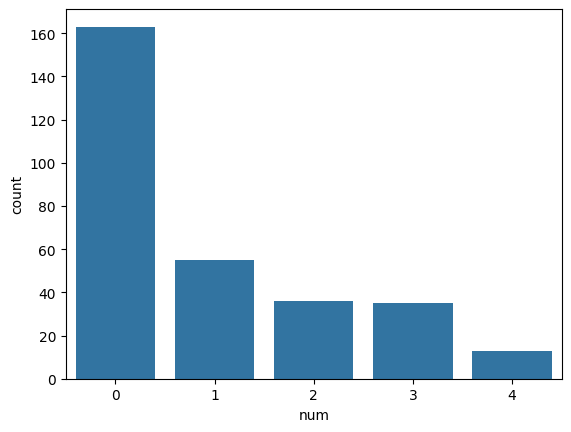

In [494]:
import seaborn as sns

# View counts of predicted values using histogram (ORIGINAL DATASET)
sns.countplot(x="num", data=dataset)

age            Axes(0.125,0.786098;0.352273x0.0939024)
sex         Axes(0.547727,0.786098;0.352273x0.0939024)
cp             Axes(0.125,0.673415;0.352273x0.0939024)
trestbps    Axes(0.547727,0.673415;0.352273x0.0939024)
chol           Axes(0.125,0.560732;0.352273x0.0939024)
fbs         Axes(0.547727,0.560732;0.352273x0.0939024)
restecg        Axes(0.125,0.448049;0.352273x0.0939024)
thalach     Axes(0.547727,0.448049;0.352273x0.0939024)
exang          Axes(0.125,0.335366;0.352273x0.0939024)
oldpeak     Axes(0.547727,0.335366;0.352273x0.0939024)
slope          Axes(0.125,0.222683;0.352273x0.0939024)
num         Axes(0.547727,0.222683;0.352273x0.0939024)
dtype: object

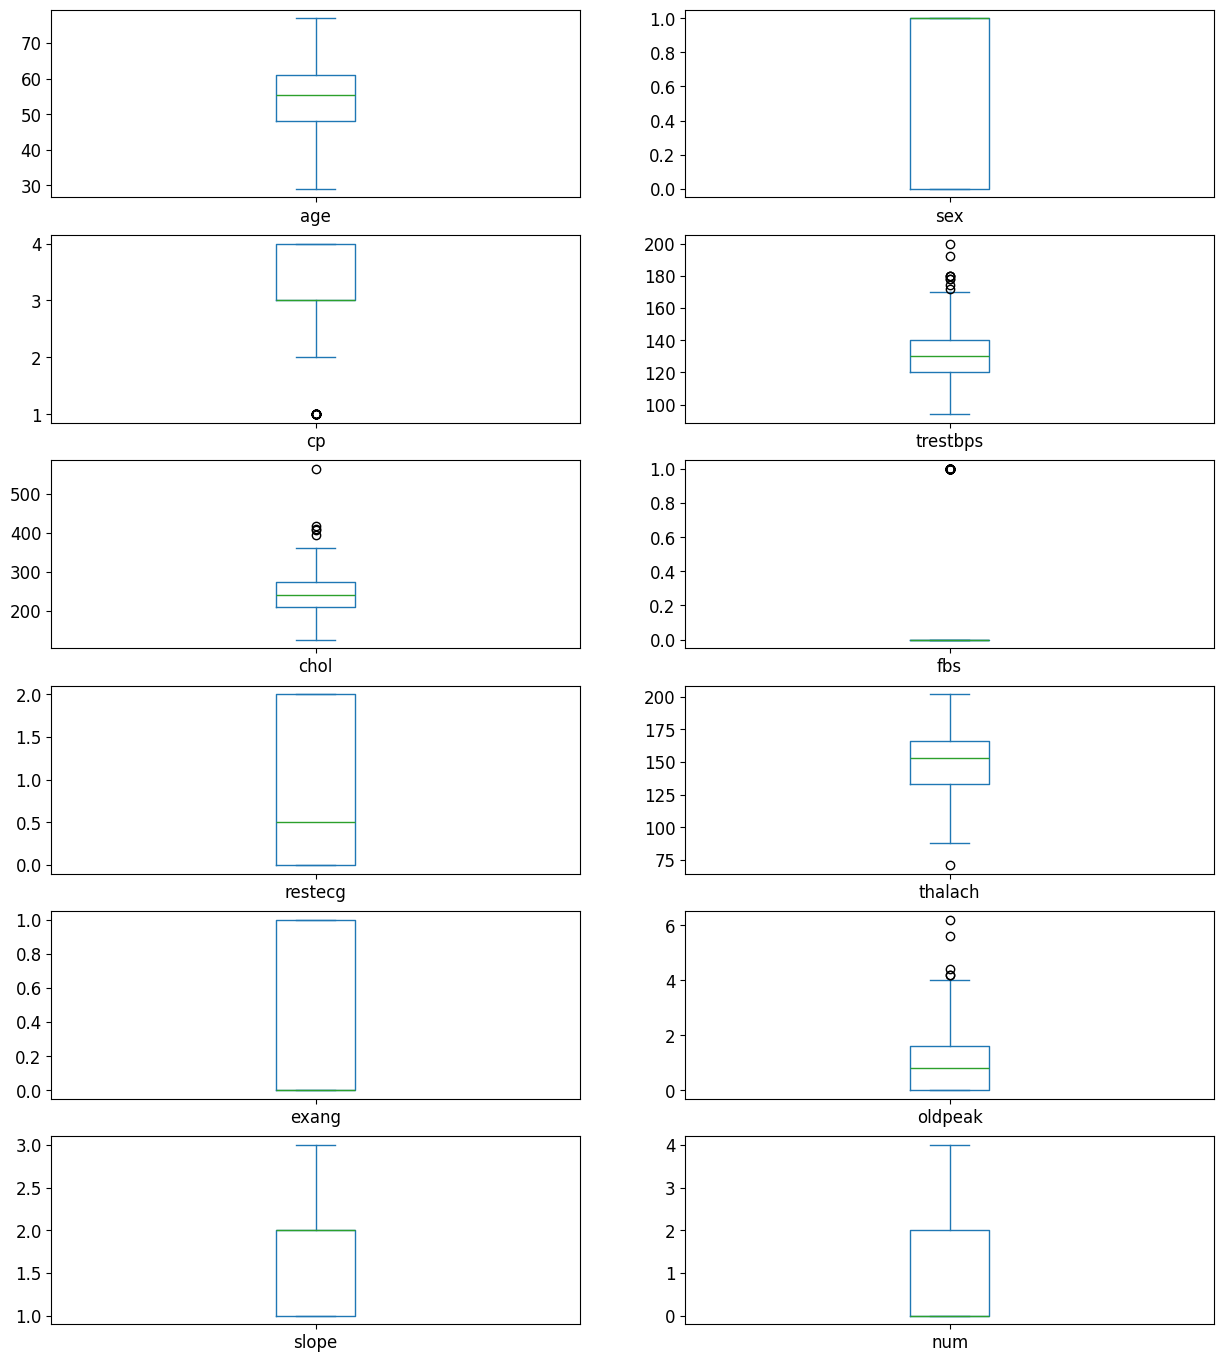

In [495]:
# View data using boxplots to see ranges and outliers (ORIGINAL DATASET)
data_mean = dataset.iloc[:, :]
data_mean.plot(kind='box', subplots=True, layout=(7,2), sharex=False,
sharey=False, fontsize=12, figsize=(15,20))

# Feature Normalisation

<Axes: >

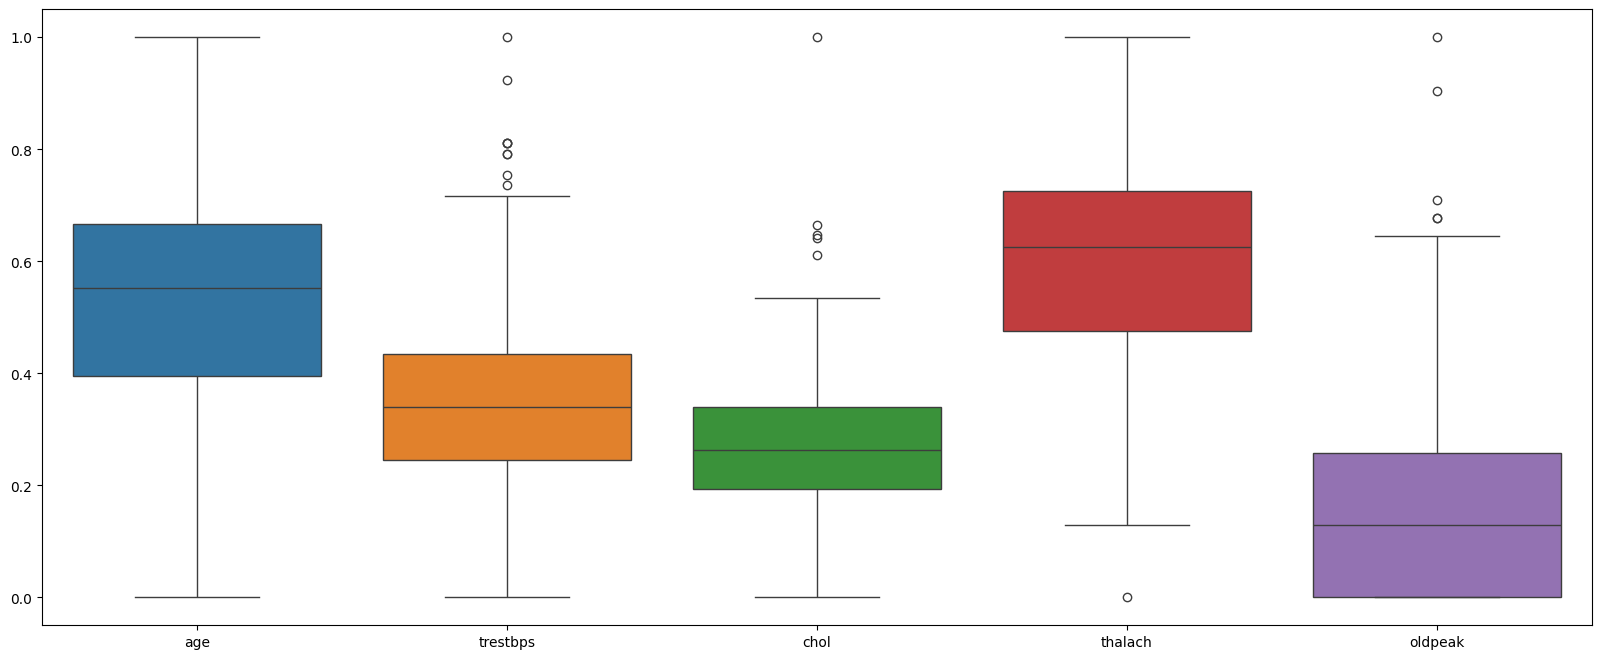

In [496]:
# Normalising numerical features to make processing faster etc (ORIGINAL DATASET)
    # age, trestbps, chol, thalach, oldpeak
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
dataset[["age", "trestbps", "chol", "thalach", "oldpeak"]] = scaler.fit_transform(dataset[["age", "trestbps", "chol", "thalach", "oldpeak"]])

# Display normalised features
fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=dataset[["age", "trestbps", "chol", "thalach", "oldpeak"]],ax=ax)

<Axes: >

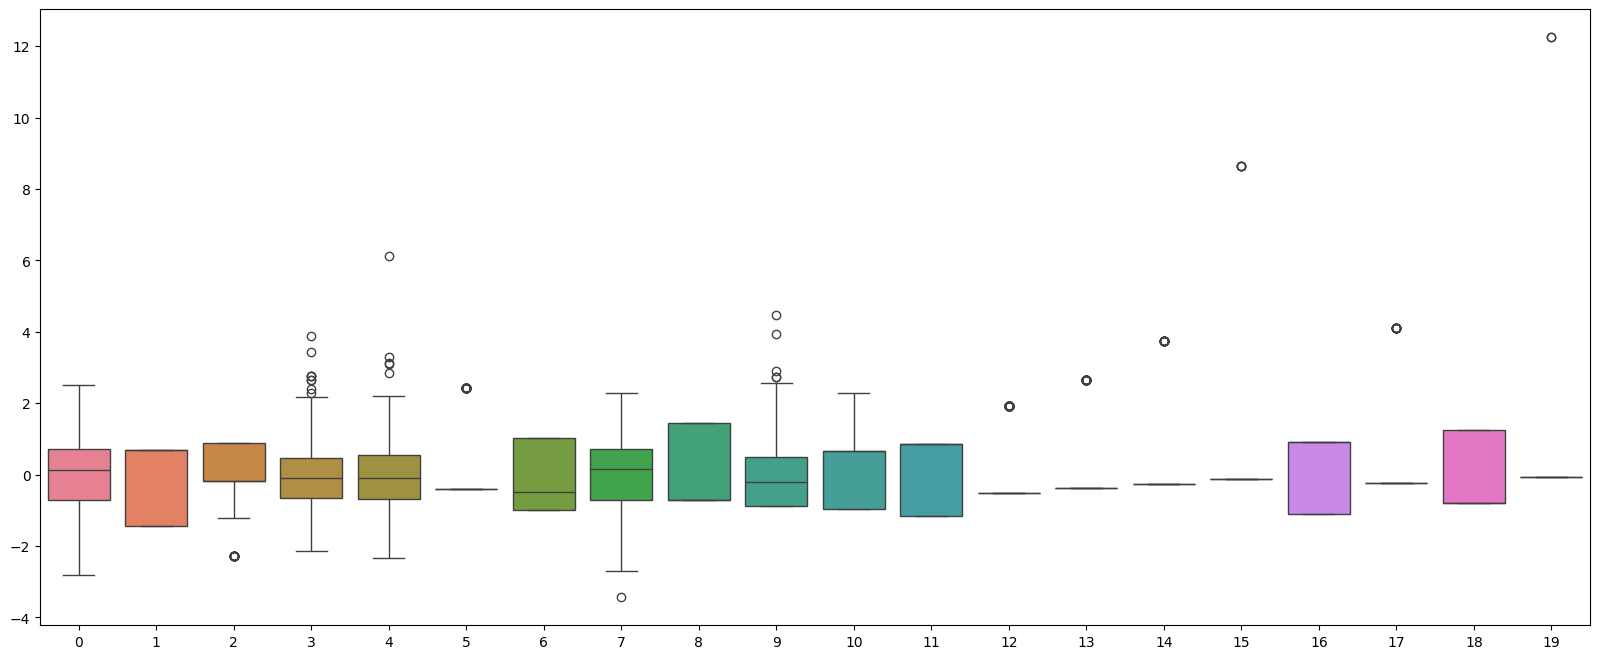

In [497]:
# Assign features to X (ONE-HOT ENCODED DATASET)
X = df_encoded.drop('num', axis=1)
# Normalise the features using zero mean normalisation to prepare it for PCA
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
# Visualise the normalised features
fig, ax=plt.subplots(1, figsize=(20,8))
sns.boxplot(data=Xs, ax=ax)

# Dimensionality Reduction

In [498]:
# Apply PCA for dimensionality reduction of the features (ONE-HOT ENCODED DATASET)
# Choose the number of retained dimensions using PCA based on how many is needed to retain 95% of
# the cumulative variance

from sklearn.decomposition import PCA


pca = PCA(n_components = 0.95)
Xs_reduced = pca.fit_transform(Xs)
print("Explained variance:", pca.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca.explained_variance_ratio_))

Explained variance: [0.18537573 0.09007717 0.07816499 0.0687045  0.06372432 0.05780333
 0.05508262 0.05262615 0.04981154 0.04813719 0.04435076 0.04108503
 0.03700894 0.03371318 0.03176216 0.02543366]
Cumulative: [0.18537573 0.2754529  0.35361789 0.42232238 0.4860467  0.54385002
 0.59893264 0.6515588  0.70137033 0.74950752 0.79385828 0.83494331
 0.87195226 0.90566544 0.9374276  0.96286126]


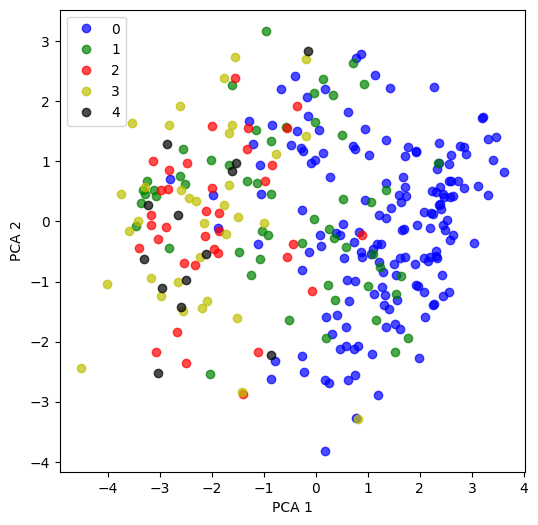

In [499]:
# Visualise the different classes using the two PCA features (ONE-HOT ENCODED DATASET)
pca_df = pd.DataFrame()
pca_df['PCA 1'] = Xs_reduced[:, 0]
pca_df['PCA 2'] = Xs_reduced[:, 1]

plt.figure(figsize = (6, 6))
plt.plot(pca_df['PCA 1'][dataset['num'] == 0], pca_df['PCA 2'][dataset['num'] == 0], 'bo', alpha = 0.7,
         markeredgecolor = 'b')
plt.plot(pca_df['PCA 1'][dataset['num'] == 1], pca_df['PCA 2'][dataset['num'] == 1], 'go', alpha = 0.7,
         markeredgecolor = 'g')
plt.plot(pca_df['PCA 1'][dataset['num'] == 2], pca_df['PCA 2'][dataset['num'] == 2], 'ro', alpha = 0.7,
         markeredgecolor = 'r')
plt.plot(pca_df['PCA 1'][dataset['num'] == 3], pca_df['PCA 2'][dataset['num'] == 3], 'yo', alpha = 0.7,
         markeredgecolor = 'y')
plt.plot(pca_df['PCA 1'][dataset['num'] == 4], pca_df['PCA 2'][dataset['num'] == 4], 'ko', alpha = 0.7,
         markeredgecolor = 'k')

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend(['0', '1', '2', '3', '4'])
        

# Correlation

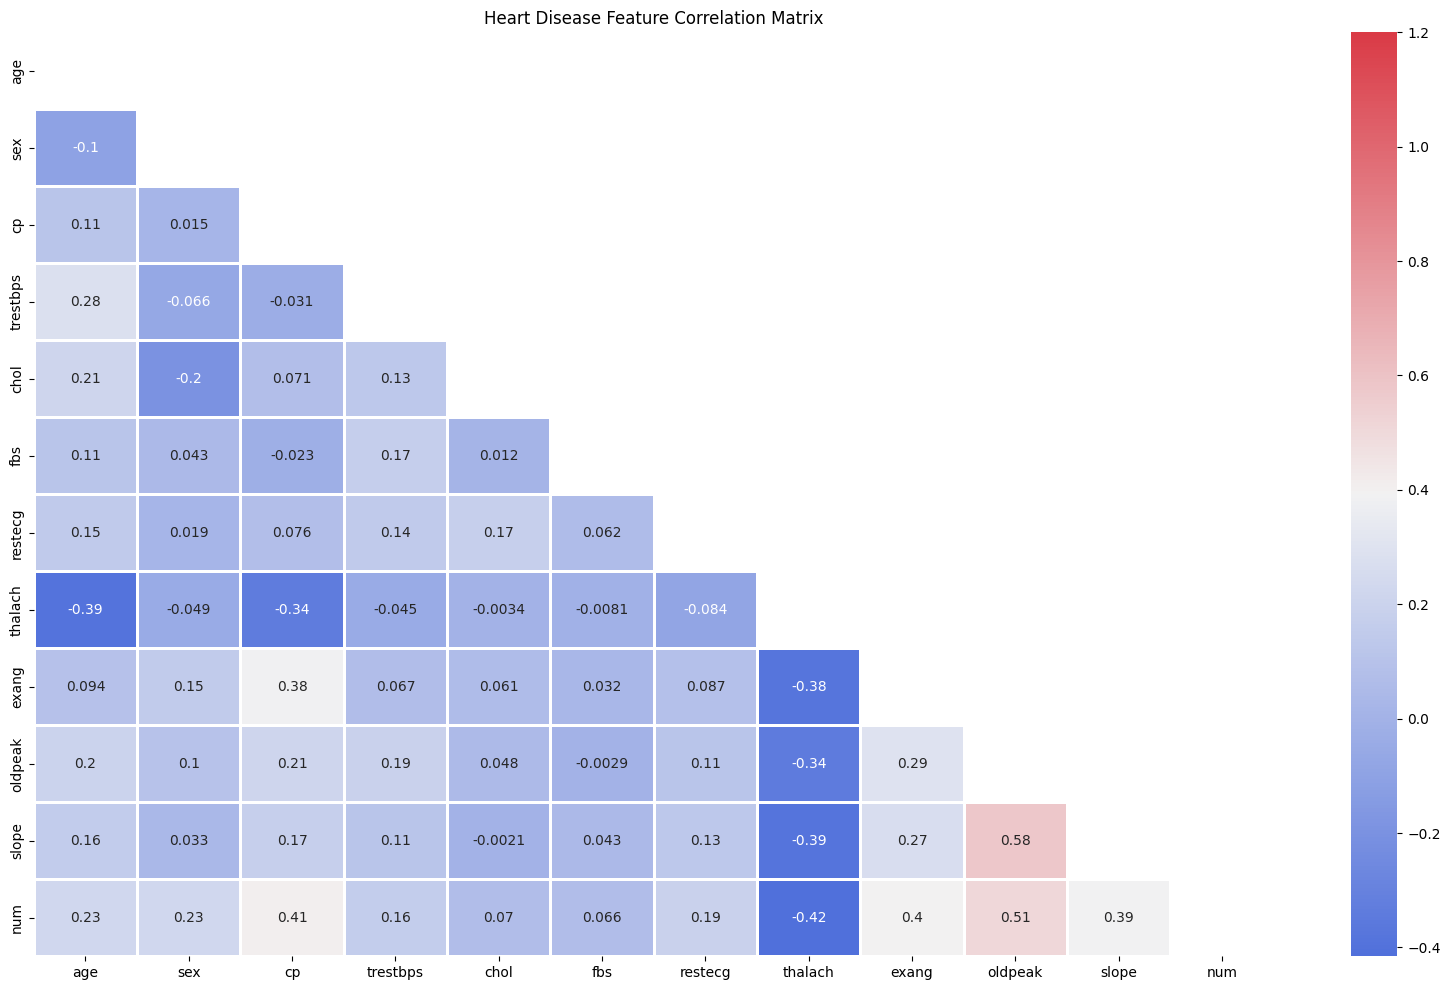

In [500]:
# Confusion Matrix (ORIGINAL DATASET)
    # Checking correlation between features

corrMatt = dataset.corr(numeric_only=True)

# Generate a mask for the upper triangle
mask = np.zeros_like(corrMatt)
mask[np.triu_indices_from(mask)] = True

# Set up the matplotlib figure
fig, ax = plt.subplots(figsize=(20, 12))
plt.title('Heart Disease Feature Correlation Matrix')

# Generate a custom diverging colormap
cmap = sns.diverging_palette(260, 10, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corrMatt, vmax=1.2, square=False, cmap=cmap, mask=mask,
ax=ax, annot=True, fmt='.2g', linewidths=1);

In [501]:
# do we remove thalach as a result? questions to pose in the essay if enough words

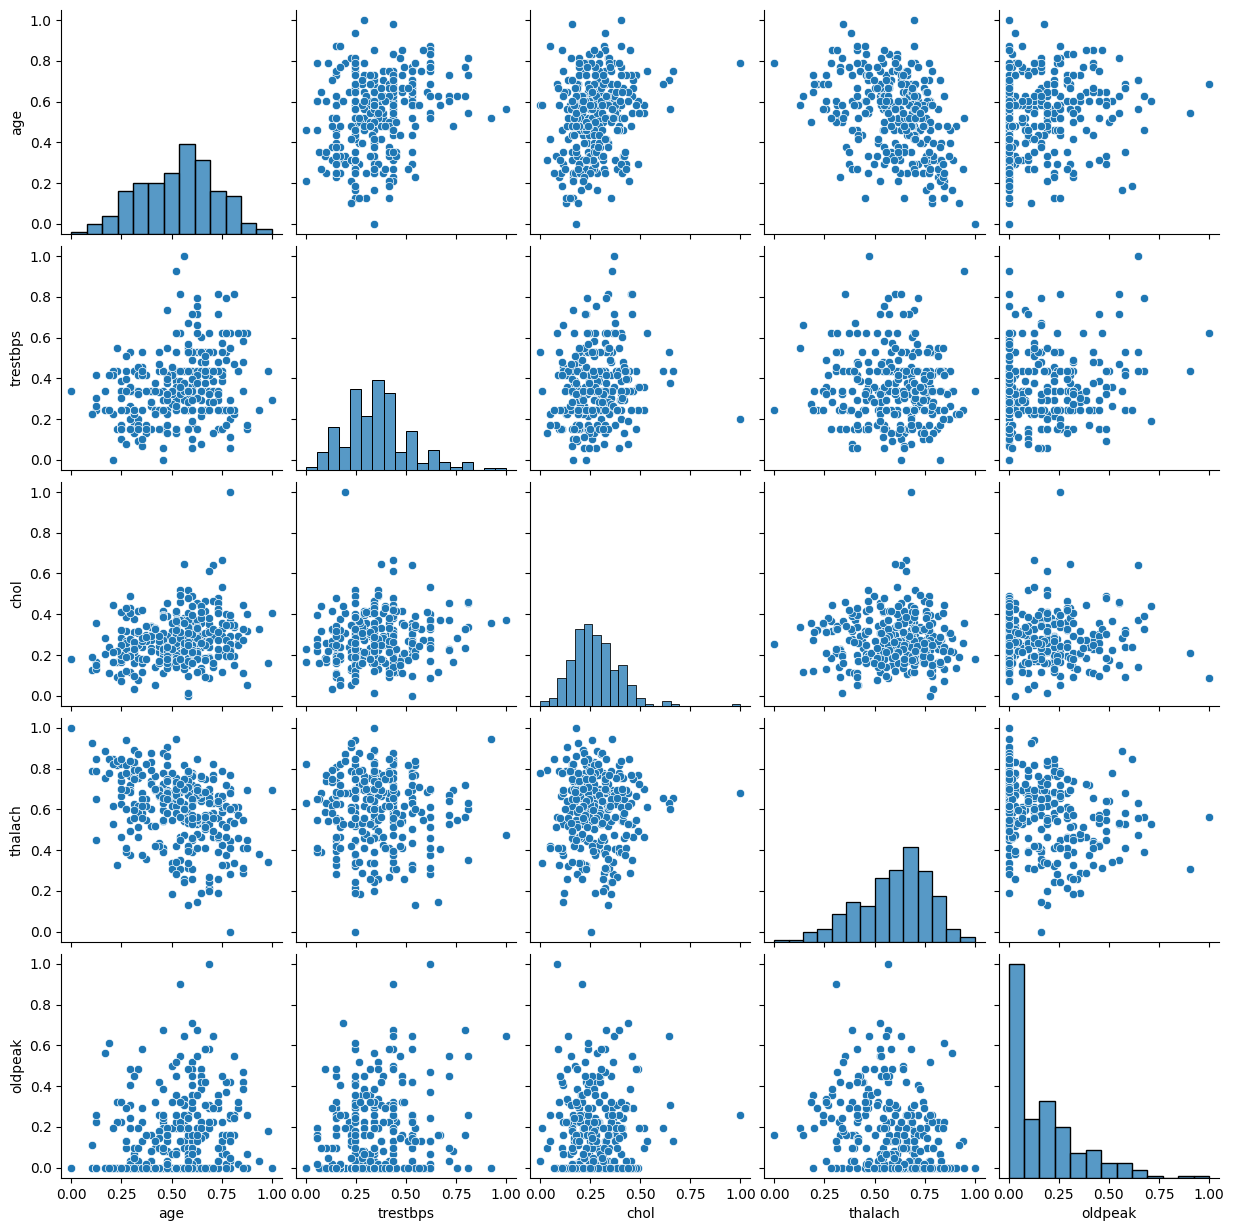

In [502]:
# Correlation-variance diagrams (ORIGINAL DATASET)
sns.pairplot(dataset[["age", "trestbps", "chol", "thalach", "oldpeak"]])

In [503]:
# Results show no clear correlation between numerical features, concerning?

# Train-Validation-Test split

In [504]:
# train-test-validation split (ORIGINAL DATASET)
# from sklearn.model_selection import train_test_split

# Xs = dataset.drop('num', axis=1) # remove num as it is the predicted class, leaving features
# y = dataset['num'] # output is the predicted class, num

# # Divide data into training (70%) and testing sets (30%)
# Xs_train, Xs_test, y_train, y_test = train_test_split(Xs, y, test_size=0.3,random_state=1, stratify=y)

In [505]:
# train-test-validation split with PCA features
from sklearn.model_selection import train_test_split

y = df_encoded['num'] # remove num as it is the predicted class, leaving only the features

# Divide data into training and testing sets, 70% and 30% split respectively 
Xs_train, Xs_test, y_train, y_test = train_test_split(Xs_reduced, y, test_size = 0.3, random_state = 1, stratify = y)

# Machine Learning Methods

In [506]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression()
log_reg.fit(Xs_train, y_train)

# Classify the test dataset and output the accuracy
classifier_score = log_reg.score(Xs_test, y_test)
print('The classifier accuracy score is {:03.2f}'.format(classifier_score))

The classifier accuracy score is 0.62


In [507]:
# Support Vector Machine
from sklearn.svm import SVC
svm_classifier = SVC(C=1.0, kernel='rbf', degree=3, gamma='auto',probability=True)
svm_classifier.fit(Xs_train, y_train)

SVC(gamma='auto', probability=True)

In [508]:
# Calculate decision function
    # Indicates distance from the hyperplane
decision_scores = svm_classifier.decision_function(Xs_test)
print("Decision Scores:", decision_scores)

Decision Scores: [[ 4.28301533  3.2336357   0.7724531   1.77334639 -0.26229582]
 [ 4.2232511   0.79813173  3.15831448  2.0641322  -0.20684551]
 [ 4.27757266  3.22237697  0.78262774  1.79735374 -0.2601852 ]
 [ 4.25239088  3.19742014  0.86888156  1.9305723  -0.26179043]
 [ 4.26442718  2.01348486  2.98985374  0.8399304  -0.24839496]
 [ 4.27664402  3.15739825  0.80385562  1.83562061 -0.2570902 ]
 [ 0.8231603   4.2467439   3.24432682  1.95006879 -0.27030267]
 [ 0.83028058  2.96192406  1.9258728   4.26239294 -0.23065953]
 [ 4.18545649  3.19434362  2.14826095  0.90433942 -0.25104903]
 [ 2.07616908  0.805369    3.11551561  4.23152753 -0.2097621 ]
 [ 3.00419466  2.07291523  0.89180633  4.2586088  -0.25532419]
 [ 4.27692931  3.18725265  1.86544772  0.78364462 -0.26188171]
 [ 4.28337788  3.21886063  0.76494488  1.78933141 -0.25885122]
 [ 4.27932795  3.19560335  0.783735    1.83022385 -0.26251766]
 [ 0.90284093  4.21604668  2.11451499  3.20422922 -0.25984523]
 [-0.25782295  3.20441318  2.03947492 

In [509]:
# Predict class labels
    # Perform prediction on the test data
from sklearn.metrics import mean_squared_error

y_pred = svm_classifier.predict(Xs_test)

svm_classifier_score = svm_classifier.score(Xs_test, y_test)
print("The classifier score of the Support Vector Machine (Classifier) is: {:03.2f}".format(svm_classifier_score))

The classifier score of the Support Vector Machine (Classifier) is: 0.63


In [510]:
# Decision Trees

# Use Decision Tree classifier to train a model. Max-depth is set to 2 so there can only be a 
# difference of 2 levels between the root node and leaf node furthest down the tree
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

tree_classifier = DecisionTreeClassifier(max_depth = 2)
tree_classifier.fit(Xs_train, y_train)

DecisionTreeClassifier(max_depth=2)

In [511]:
classifier_score = tree_classifier.score(Xs_train, y_train)
print("The classifier score of the Decision Tree for the training set is: {:03.2f}".format(classifier_score))

The classifier score of the Decision Tree for the training set is: 0.63


In [512]:
# Predict the outcome of the test set. Columns in the output array correspond to the probabiility
# that the test data is classified as the respective label
tree_classifier.predict_proba(Xs_test)

array([[0.97916667, 0.02083333, 0.        , 0.        , 0.        ],
       [0.13432836, 0.26865672, 0.20895522, 0.31343284, 0.07462687],
       [0.97916667, 0.02083333, 0.        , 0.        , 0.        ],
       [0.69135802, 0.2345679 , 0.02469136, 0.03703704, 0.01234568],
       [0.69135802, 0.2345679 , 0.02469136, 0.03703704, 0.01234568],
       [0.97916667, 0.02083333, 0.        , 0.        , 0.        ],
       [0.13432836, 0.26865672, 0.20895522, 0.31343284, 0.07462687],
       [0.13432836, 0.26865672, 0.20895522, 0.31343284, 0.07462687],
       [0.13432836, 0.26865672, 0.20895522, 0.31343284, 0.07462687],
       [0.13432836, 0.26865672, 0.20895522, 0.31343284, 0.07462687],
       [0.13432836, 0.26865672, 0.20895522, 0.31343284, 0.07462687],
       [0.69135802, 0.2345679 , 0.02469136, 0.03703704, 0.01234568],
       [0.97916667, 0.02083333, 0.        , 0.        , 0.        ],
       [0.69135802, 0.2345679 , 0.02469136, 0.03703704, 0.01234568],
       [0.13432836, 0.26865672, 0.

In [513]:
# Classify the test dataset and output the accuracy score
classifier_score = tree_classifier.score(Xs_test, y_test)
print("The classifier score of the Decision Tree is: {:03.2f}".format(classifier_score))

The classifier score of the Decision Tree is: 0.64


[Text(0.5, 0.8333333333333334, 'x[0] <= -0.364\ngini = 0.646\nsamples = 211\nvalue = [114, 38, 25, 25, 9]'),
 Text(0.25, 0.5, 'x[12] <= 0.778\ngini = 0.774\nsamples = 82\nvalue = [11.0, 18.0, 23.0, 22.0, 8.0]'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.762\nsamples = 67\nvalue = [9, 18, 14, 21, 5]'),
 Text(0.375, 0.16666666666666666, 'gini = 0.578\nsamples = 15\nvalue = [2, 0, 9, 1, 3]'),
 Text(0.75, 0.5, 'x[0] <= 1.648\ngini = 0.338\nsamples = 129\nvalue = [103, 20, 2, 3, 1]'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.465\nsamples = 81\nvalue = [56, 19, 2, 3, 1]'),
 Text(0.875, 0.16666666666666666, 'gini = 0.041\nsamples = 48\nvalue = [47, 1, 0, 0, 0]')]

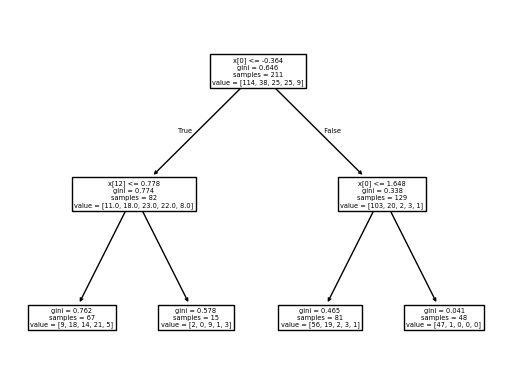

In [514]:
# Visualise the trained Decision Tree
tree.plot_tree(tree_classifier)

In [515]:
# Neural Network
from sklearn.neural_network import MLPClassifier

# Use Multi Layer Perceptron Neural Network classifier to train a model
mlp_classifier = MLPClassifier(random_state = 1, max_iter = 1000).fit(Xs_train, y_train)


In [516]:
# Predict the outcome of the test set. Columns in the output array correspond to the probabiility
# that the test data is classified as the respective label
mlp_classifier.predict_proba(Xs_test)

array([[9.57860540e-01, 4.21376698e-02, 1.13765658e-07, 4.23516010e-07,
        1.25324619e-06],
       [9.94569697e-01, 1.78695937e-06, 6.15900144e-04, 4.78231942e-03,
        3.02960498e-05],
       [9.96338813e-01, 3.65885263e-03, 6.79056096e-08, 7.47915769e-07,
        1.51828444e-06],
       [9.92002533e-01, 6.87357837e-03, 4.92704397e-04, 6.20670585e-04,
        1.05139689e-05],
       [9.88068612e-01, 1.19272716e-02, 1.81503527e-06, 3.99024645e-09,
        2.29734420e-06],
       [9.99663016e-01, 2.52999206e-04, 1.97380177e-07, 8.34640343e-05,
        3.23792822e-07],
       [3.64421070e-02, 5.34321445e-01, 3.86029885e-01, 4.30719261e-02,
        1.34636677e-04],
       [7.97766070e-05, 1.11774722e-03, 1.98916002e-02, 7.82037164e-01,
        1.96873712e-01],
       [6.25756542e-02, 2.25796200e-01, 5.35168578e-01, 1.52168120e-01,
        2.42914475e-02],
       [6.54086017e-03, 5.20339063e-03, 1.36674041e-02, 9.67697811e-01,
        6.89053371e-03],
       [9.31336767e-03, 5.6273

In [517]:
# Classify the test dataset the Multi Layer Perceptron Network and output the accuracy score
classifier_score = mlp_classifier.score(Xs_test, y_test)
print("The classifier accuracy score of the Multi Layer Perceptron is {:03.2f}".format(classifier_score))

The classifier accuracy score of the Multi Layer Perceptron is 0.60


# K-fold Cross Validation (Method Evaluation)

In [518]:
# k-fold cross-validation
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.svm import SVC

scaler = StandardScaler()
df_encoded_scaled = pd.DataFrame(scaler.fit_transform(df_encoded), columns=df_encoded.columns)


In [519]:
# k-fold cross-validation (LAB 5 METHOD 1)

from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC

n_folds = 5
models_old = {svm_classifier, log_reg, tree_classifier, mlp_classifier}
for model in models_old:
    scores = cross_val_score(model, df_encoded_scaled, y, cv=5)
    print(scores)
    avg = (100 * np.mean(scores), 100 * np.std(scores)/np.sqrt(scores.shape[0]))
    print("Average score and standard deviation: (%.2f +- %.3f)%%" %avg)

[0.8852459  0.83606557 0.81666667 0.88333333 0.88333333]
Average score and standard deviation: (86.09 +- 1.292)%
[0.75409836 0.70491803 0.66666667 0.75       0.65      ]
Average score and standard deviation: (70.51 +- 1.890)%
[0.81967213 0.80327869 0.78333333 0.83333333 0.73333333]
Average score and standard deviation: (79.46 +- 1.560)%
[0.83606557 0.83606557 0.85       0.85       0.83333333]
Average score and standard deviation: (84.11 +- 0.328)%


In [520]:
# Dictionary that contains original models
models = {
    "Logistic Regression": log_reg,
    "SVM (RBF Kernel)": svm_classifier,
    "Decision Tree": tree_classifier,
    "MLP Classifier": mlp_classifier
}   

In [521]:
# (LAB 5 METHOD 2)

kf = KFold(n_splits=5, shuffle=True, random_state=42)

conf_matrices = {name: np.zeros((5,5), dtype=int) for name in models.keys()}

for name, model in models.items():
    print(f"\n== {name} ==")
    y_true_all, y_prob_all = [], []

    fold = 1

    for fold, (train_index, test_index) in enumerate(kf.split(df_encoded_scaled, y), 1):
        X_train, X_test = df_encoded_scaled.iloc[train_index], df_encoded_scaled.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]  # For ROC curves

        # Confusion matrix for this fold
        cm_fold = confusion_matrix(y_test, y_pred, labels=[0,1,2,3,4])
        conf_matrices[name] += cm_fold
        print(f"\nFold {fold} confusion matrix:\n{cm_fold}")

        print(f"Fold {fold} accuracy: {accuracy_score(y_test, y_pred):.3f}")

        fold += 1


== Logistic Regression ==

Fold 1 confusion matrix:
[[31  1  0  0  0]
 [ 0  8  1  0  0]
 [ 0  3  3  2  0]
 [ 0  0  1  5  3]
 [ 0  0  0  1  2]]
Fold 1 accuracy: 0.803

Fold 2 confusion matrix:
[[33  0  0  0  0]
 [ 1 10  3  0  0]
 [ 0  3  2  2  0]
 [ 0  0  2  5  0]
 [ 0  0  0  0  0]]
Fold 2 accuracy: 0.820

Fold 3 confusion matrix:
[[34  0  0  0  0]
 [ 0  8  0  0  0]
 [ 0  4  3  1  0]
 [ 0  0  0  7  0]
 [ 0  0  0  1  2]]
Fold 3 accuracy: 0.900

Fold 4 confusion matrix:
[[28  0  0  0  0]
 [ 0  7  3  0  0]
 [ 0  0  6  3  0]
 [ 0  0  3  5  0]
 [ 0  0  0  5  0]]
Fold 4 accuracy: 0.767

Fold 5 confusion matrix:
[[36  0  0  0  0]
 [ 1 10  3  0  0]
 [ 0  2  1  1  0]
 [ 0  0  1  3  0]
 [ 0  0  0  1  1]]
Fold 5 accuracy: 0.850

== SVM (RBF Kernel) ==

Fold 1 confusion matrix:
[[31  1  0  0  0]
 [ 4  5  0  0  0]
 [ 0  5  2  1  0]
 [ 0  0  3  6  0]
 [ 0  0  1  2  0]]
Fold 1 accuracy: 0.721

Fold 2 confusion matrix:
[[32  0  1  0  0]
 [ 8  3  3  0  0]
 [ 1  3  1  2  0]
 [ 0  0  4  3  0]
 [ 0  0  0 

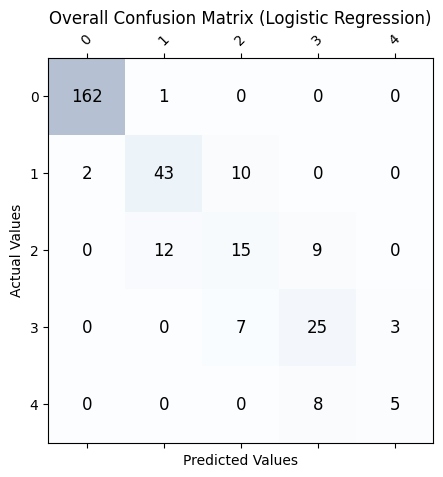

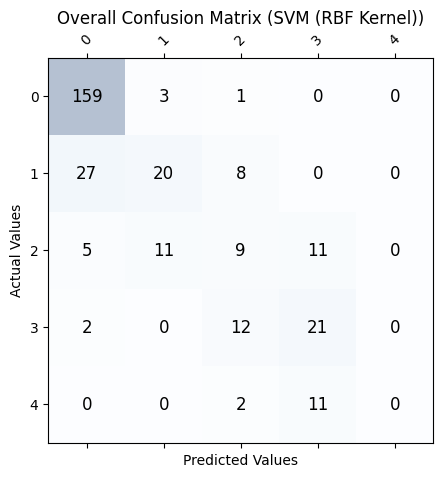

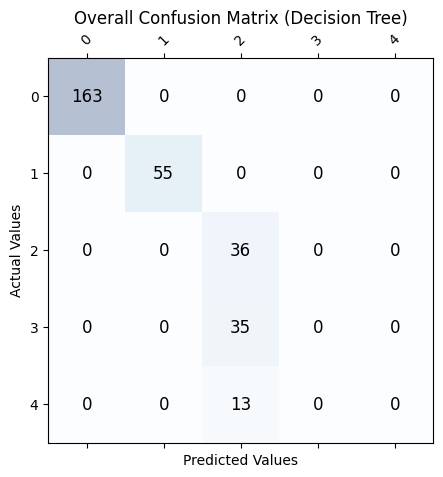

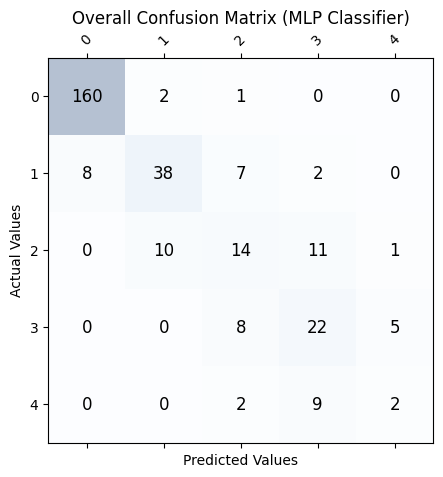

              precision    recall  f1-score   support

           0       0.95      1.00      0.97        36
           1       1.00      0.71      0.83        14
           2       0.25      0.25      0.25         4
           3       0.50      0.75      0.60         4
           4       0.00      0.00      0.00         2

    accuracy                           0.83        60
   macro avg       0.54      0.54      0.53        60
weighted avg       0.85      0.83      0.83        60



In [522]:
# Confusion Matrix

for name, cm_total in conf_matrices.items():
    fig, ax = plt.subplots(figsize=(5,5))
    ax.matshow(cm_total, cmap=plt.cm.Blues, alpha=0.3)
    
    for i in range(cm_total.shape[0]):
        for j in range(cm_total.shape[1]):
            ax.text(x=j, y=i, s=cm_total[i, j], va='center', ha='center', fontsize=12)
    
    classes = ["0", "1", "2", "3", "4"]
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)
    plt.xlabel('Predicted Values')
    plt.ylabel('Actual Values')
    plt.title(f'Overall Confusion Matrix ({name})')
    plt.show()

print(classification_report(y_test, y_pred, labels=[0,1,2,3,4]))   